# End-to-End Adaptive Optics with **Soapy** — Part 2 

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GillesOrban/ao_school/blob/main/soapy_lab.ipynb)

Part 1 (`aotools_lab.ipynb`) built the ingredients. 

Here we assemble them into a **full end-to-end AO loop** with [soapy](https://github.com/AOtools/soapy).

## Run this cell first
Run the cell below if you run the notebook on on Google Colab.
Skip if you run the notebook locally

In [ ]:
!pip install aotools pyfftw pyyaml numba pyqtgraph

# 2. Install soapy from GitHub
!pip install git+https://github.com/AOtools/soapy.git

# 3. Verify
import soapy
print("soapy OK")

!git clone https://github.com/GillesOrban/ao_school.git
%cd ao_school

## What is Soapy ?

- an end-to-end adaptive optics simulator in Python.
- Full documentation can be found [here](https://soapy.readthedocs.io/en/latest/)
- Full package can be found [here](https://github.com/AOtools/soapy)
- A set of notebooks for tests and example can be found [here](https://github.com/AOtools/soapytest)


### Objectives
1. soapy architecture: 
   1. one YAML config in `conf/` (see on GitHub, look for example at `sh_8X8.yaml`). **NB: on Colab the yaml files will be in `/contents/ao_school/conf/`**
   2. one `Sim` object with main functions `aoinit()` / `makeIMat()` / `aoloop()`.
2. Read/modify the config or in Python.
3. Open loop: slopes, spot pattern, seeing-limited PSF, WFE.
4. Calibration: acquisition of the interaction matrix pokes
5. Closed loop: gain/delay/$r_0$ sweeps; error budgets (fitting, aliasing, temporal).
6. Extras: pyramid WFS (`conf/pwfs.yaml`), modal DM (`Zernike`/`KarhunenLoeve`).



## 0. Setup — the `soapy` toolbox
For an introduction of the architecture, check here: https://soapy.readthedocs.io/en/latest/architecture.html

`soapy` is setup by a configuration file (yaml format): one config → one `Sim`; 

Wavefront sensors (WFSs), Deformable Mirror (DMs), reconstructors are interchangeable blocks:

| Module | Classes |
|---|---|
| `soapy` (+ `confParse`, `lineofsight`) | `Sim`, `loadSoapyConfig`, `make_mask`, `YAML_Configurator`, `LineOfSight` |
| `soapy.atmosphere` | `atmos`, `moveScrns()`, frozen-flow infinite screens |
| `soapy.wfs` | `ShackHartmann`, `Pyramid`, `Gradient`, `Zernike`, `ExtendedSH` |
| `soapy.DM` | `TT`, `FastPiezo`, `GaussStack`, `Zernike`, `KarhunenLoeve`, `CustomShapes` |
| `soapy.reconstruction` | `MVM`, `MVM_SeparateDMs`, `LearnAndApply`, `WooferTweeter`, `ANN` |
| `soapy.scienceinstrument` | `PSFCamera`, `singleModeFibre` |

Here: configs in `conf/`; more configs + tests in `soapytest` repo.

Docs: http://soapy.readthedocs.io; 

CLI: `soapy conf/sh_8x8.yaml`.


In [2]:
# ============================================================
# Setup — run this cell first
# ============================================================
%matplotlib inline

import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import soapy     # end-to-end AO simulator (assets/soapy)
import aotools   # reused from Part 1 (r0 <-> seeing conversions)

print('soapy   :', soapy.__version__)
print('aotools :', aotools.__version__)
print('numpy   :', np.__version__)

plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['image.origin'] = 'lower'
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['figure.max_open_warning'] = 0   # this notebook opens many figures

def logim(im, floor=1e-12):
    # log10 of an image, floored so the far PSF wings don't give log10(0) warnings
    return np.log10(np.maximum(im, floor))

def soapy_conf(name):
    # Locate a config file in this repo's conf/ directory, searching upwards from the cwd
    candidates = [os.path.join('conf', name)]
    d = os.getcwd()
    for _ in range(4):
        candidates.append(os.path.join(d, 'conf', name))
        d = os.path.dirname(d)
    for c in candidates:
        if os.path.exists(c):
            print('config found:', c)
            return c
    raise FileNotFoundError(name + ' not found in conf/ — run from the ao_school repo')

def crop_to_pupil(a, sim):
    # Central simSize x simSize slice of a (larger) scrnSize screen — the part matching sim.mask.
    s = sim.config.sim.simSize
    c = a.shape[0] // 2
    return a[c - s//2 : c + s//2, c - s//2 : c + s//2]

def subap_centres(sim, wfs):
    # Determine the centres of the active sub-apertures in the sim-array frame, as (col, row)
    # Soapy stores the sub-aperture *corners* in the pupil array (wfs.pupil_subap_coords), 
    # so add half a sub-aperture and then the simPad offset to reach the sim.mask frame.
    pad = sim.config.sim.simPad
    sp = sim.config.sim.pupilSize / wfs.nx_subaps          # px per subap across the pupil
    c = wfs.pupil_subap_coords.astype(float) + 0.5 * sp    # corners -> centres
    return c[:, 1] + pad, c[:, 0] + pad                    # (col, row)


soapy   : 0.14.0+7.g36588ed.dirty
aotools : 0.1.dev477+g8f38ff7c1.d20260605
numpy   : 2.4.2


---
# Section 1 — The working principle of soapy (~15 min)

One YAML config → one `Sim`. 

Each `loopFrame()`: 
- Move the atmosphere with `moveScrns()` 
- WFS measures residual slopes 
- Compute the command `commands = cMat^T . slopes` 
- Apply the DM commands (delayed `loopDelay` frames)
- Compute the DM shape 
- Propagate to the science camera. 
Closed loop: the DM shape is subtracted from the next frame's turbulence.

Workflow (also what the CLI does):
```
    sim = soapy.Sim("conf/sh_8x8.yaml")    # 1. read config
    sim.aoinit()                           # 2. build all objects
    sim.makeIMat()                         # 3. calibration: D -> R
    sim.aoloop()                           # 4. run nIters frames
```

All data lives on the `sim` object as Python attributes:

| Data | Attribute |
|---|---|
| pupil mask / screens [nm @500 nm] | `sim.mask` / `sim.atmos.scrns`, `sim.scrns` |
| slopes [subap px] / spot pattern | `sim.slopes`, `sim.allSlopes` / `sim.wfss[0].wfsDetectorPlane` |
| DM commands / shapes | `sim.dmCommands`, `sim.allDmCommands`, `sim.combinedCorrection` |
| sci PSF (long/inst), residual phase [nm] | `sim.sciImgs[0]`, `sim.sciImgsInst[0]`, `sim.sciPhase[0]` |
| Strehl inst/long, WFE [nm], EE50 [arcsec] | `sim.instStrehl[0]`, `sim.longStrehl[0]`, `sim.WFE[0]`, `sim.ee50d[0]` |
| calibration matrices | `sim.recon.interaction_matrix`, `sim.recon.control_matrix` |


### 1.1 Anatomy of a YAML config

One config, split into sections; anything can be overridden in Python after loading :

| Section | Key parameters |
|---|---|
| top level | `pupilSize`, `nGS/nDM/nSci`, `nIters`, `loopTime`, `loopDelay`, `simName`, `save*` |
| `Atmosphere` | heights/strengths/winds, `r0`, `L0`, `wholeScrnSize`, `infinite`, `randomSeed` |
| `Telescope` | `telDiam`, `obsDiam`, `mask` |
| `WFS` | `type`, `GSPosition`, `nxSubaps`, `pxlsPerSubap`, `subapFOV`, `wavelength` |
| `DM` / `Reconstructor` | `type`, `closed`, `nxActuators`, `iMatValue`, `gain` / `svdConditioning` |
| `Science` | `position`, `FOV` [arcsec], `wavelength`, `pxls` |


See the full list of configuration parameters: https://soapy.readthedocs.io/en/latest/Configuration.html

In [3]:
# --- 1.1 Load a config file and inspect the parsed parameters -------------
# 'sh_8x8.yaml' is in conf/
conf_file = soapy_conf('sh_8x8.yaml')

config = soapy.loadSoapyConfig(conf_file)

print('--- sim (top level) ---')
for p in ['pupilSize', 'nGS', 'nDM', 'nSci', 'nIters', 'loopTime', 'loopDelay', 'simName', 'verbosity']:
    print(f'  {p:12s} = {getattr(config.sim, p, "<default>")}')

print('--- Atmosphere ---')
for p in ['scrnNo', 'scrnHeights', 'scrnStrengths', 'windDirs', 'windSpeeds', 'r0', 'L0', 'infinite', 'randomSeed']:
    print(f'  {p:15s} = {getattr(config.atmos, p, "<default>")}')

print('--- Telescope ---')
print(f'  telDiam = {config.tel.telDiam} m, obsDiam = {config.tel.obsDiam} m, mask = {config.tel.mask}')

w = config.wfss[0]
print('--- WFS 0 ---')
print(f'  type = {w.type}, GSPosition = {w.GSPosition}, GSHeight = {w.GSHeight}, GSMag = {w.GSMag}')
print(f'  nxSubaps = {w.nxSubaps}, pxlsPerSubap = {w.pxlsPerSubap}, subapFOV = {w.subapFOV} arcsec, '
      f'wavelength = {w.wavelength*1e9:.0f} nm, propagationMode = {w.propagationMode}')

print('--- DMs ---')
for d, dm in enumerate(config.dms):
    print(f'  DM {d}: type = {dm.type}, closed = {dm.closed}, nxActuators = {dm.nxActuators}, '
          f'iMatValue = {dm.iMatValue}, gain = {dm.gain}')

print('--- Reconstructor / Science ---')
print(f'  recon: type = {config.recon.type}, svdConditioning = {config.recon.svdConditioning}, gain = {config.recon.gain}')
s = config.scis[0]
print(f'  sci 0: position = {s.position}, FOV = {s.FOV} arcsec, wavelength = {s.wavelength*1e6:.2f} um, pxls = {s.pxls}')


config found: conf/sh_8x8.yaml
--- sim (top level) ---
  pupilSize    = 100
  nGS          = 1
  nDM          = 2
  nSci         = 1
  nIters       = 500
  loopTime     = 0.0025
  loopDelay    = 0
  simName      = None
  verbosity    = 2
--- Atmosphere ---
  scrnNo          = 4
  scrnHeights     = [    0  5000 10000 15000]
  scrnStrengths   = [0.5 0.3 0.1 0.1]
  windDirs        = [  0  45  90 135]
  windSpeeds      = [10 10 15 20]
  r0              = 0.16
  L0              = [20 20 20 20]
  infinite        = True
  randomSeed      = None
--- Telescope ---
  telDiam = 2.4 m, obsDiam = 0 m, mask = circle
--- WFS 0 ---
  type = ShackHartmann, GSPosition = [0 0], GSHeight = 0, GSMag = 8
  nxSubaps = 8, pxlsPerSubap = 10, subapFOV = 2.5 arcsec, wavelength = 600 nm, propagationMode = Geometric
--- DMs ---
  DM 0: type = TT, closed = True, nxActuators = None, iMatValue = 0.25, gain = 0.5
  DM 1: type = FastPiezo, closed = True, nxActuators = 9, iMatValue = 500.0, gain = 0.5
--- Reconstructor 

In [4]:
# --- 1.1b The same config, edited in Python before aoinit() ---------------
# (this is exactly what the soapy tests in assets/soapy/test/ do)
sim = soapy.Sim(conf_file)

# Keep the run light, reproducible, and silent on disk:
sim.config.sim.simName  = None    # no FITS output directory
sim.config.sim.logfile  = None
sim.config.sim.verbosity = 1
sim.config.sim.nIters   = 300     # loop frames (5000 in the shipped file)
sim.config.atmos.randomSeed = 0   # reproducible atmosphere

# Turn on the data streams we want to analyse afterwards
sim.config.sim.saveSlopes     = True
sim.config.sim.saveDmCommands = True
sim.config.sim.saveInstPsf    = True
sim.config.sim.saveSciRes     = True

print('overridden: nIters =', sim.config.sim.nIters, '| randomSeed =', sim.config.atmos.randomSeed)

# The raw YAML of the reference config (first lines)
with open(conf_file) as f:
    txt = f.read()
print()
print('--- raw YAML, first 40 lines of', conf_file.split('/')[-1], '---')
print('\n'.join(txt.splitlines()[:100]))


overridden: nIters = 300 | randomSeed = 0

--- raw YAML, first 40 lines of sh_8x8.yaml ---
simName:               # if simName is not defined (None) data are not saved
pupilSize: 100
nGS: 1
nDM: 2
nSci: 1
nIters: 500
loopTime: 0.0025
threads: 4

verbosity: 2

saveCMat: True
saveSlopes: True
saveDmCommands:   True
saveLgsPsf: True
saveInstPsf: True
saveSciPsf: True
saveSciRes: True


Atmosphere:
  scrnNo: 4
  scrnHeights: [0, 5000, 10000, 15000]
  scrnStrengths: [0.5, 0.3, 0.1, 0.1]
  windDirs: [0, 45, 90, 135]
  windSpeeds: [10, 10, 15, 20]
  wholeScrnSize: 2048
  r0: 0.16
  L0: [20, 20, 20, 20]
  infinite: True


Telescope:
  telDiam: 2.4
  obsDiam: 0 #2.1
  mask: circle

WFS:
  0:
    type: ShackHartmann
    GSPosition: [0, 0]
    GSHeight: 0
    GSMag: 8
    nxSubaps: 8
    pxlsPerSubap: 10
    subapFOV: 2.5
    wavelength: 600e-9
    photonNoise: False

DM:
  0:
    type: TT
    closed: True
    gain: 0.5
    iMatValue: 0.25


  1:
    type: FastPiezo
    closed: True
    nxActuato

### 1.2 `aoinit()` — building the AO system

`aoinit()` instantiates everything from the config: 
- pupil mask (`sim.mask`), 
- atmosphere (`sim.atmos`, frozen-flow layers extruded with `infinite: True`), 
- WFSs (`sim.wfss`), 
- DMs (`sim.dms`), 
- reconstructor (`sim.recon`), 
- science cameras (`sim.sciCams`).

In [5]:
# --- 1.2 aoinit: build the system, then take inventory --------------------
sim.aoinit()

print(f'pupil mask : sim.mask {sim.mask.shape}, {int(sim.mask.sum())} illuminated px, '
      f'simSize = {sim.config.sim.simSize}, scrnSize = {sim.config.sim.scrnSize}')
print(f'pixel scale: {sim.config.sim.pxlScale:.2f} px/m = {1/sim.config.sim.pxlScale*100:.1f} cm/px')
print(f'atmosphere : {sim.atmos.scrnNo} layers, r0 = {sim.atmos.r0} m @ 500 nm, '
      f'screens {sim.atmos.scrn_size}x{sim.atmos.scrn_size}, infinite = {sim.config.atmos.infinite}')
for n, wfs in sim.wfss.items():
    print(f'WFS {n}      : {type(wfs).__name__}, {wfs.n_subaps} active subaps on a {wfs.nx_subaps}x{wfs.nx_subaps} grid '
          f'-> {wfs.n_measurements} measurements, subap diam = {wfs.subap_diam:.2f} m, '
          f'wfs px scale = {wfs.pixel_scale:.3f} arcsec/px')
for d, dm in sim.dms.items():
    print(f'DM {d}      : {type(dm).__name__}, {dm.n_acts} actuators, closed = {dm.dmConfig.closed}')
print(f'recon      : {type(sim.recon).__name__}')
for n, sci in sim.sciCams.items():
    print(f'sci cam {n} : {type(sci).__name__}, {sci.nx_pixels}x{sci.nx_pixels} px, FOV = {sci.fov} arcsec')


pupil mask : sim.mask (102, 102), 7860 illuminated px, simSize = 102, scrnSize = 102
pixel scale: 41.67 px/m = 2.4 cm/px
atmosphere : 4 layers, r0 = 0.16 m @ 500 nm, screens 102x102, infinite = True
WFS 0      : ShackHartmann, 52 active subaps on a 8x8 grid -> 104 measurements, subap diam = 0.30 m, wfs px scale = 0.250 arcsec/px
DM 0      : TT, 2 actuators, closed = True
DM 1      : FastPiezo, 81 actuators, closed = True
recon      : MVM
sci cam 0 : PSFCamera, 64x64 px, FOV = 1.0 arcsec


phase screens: (4, 102, 102) -> units: nm
layer 0 rms over the screen: 236.4 nm


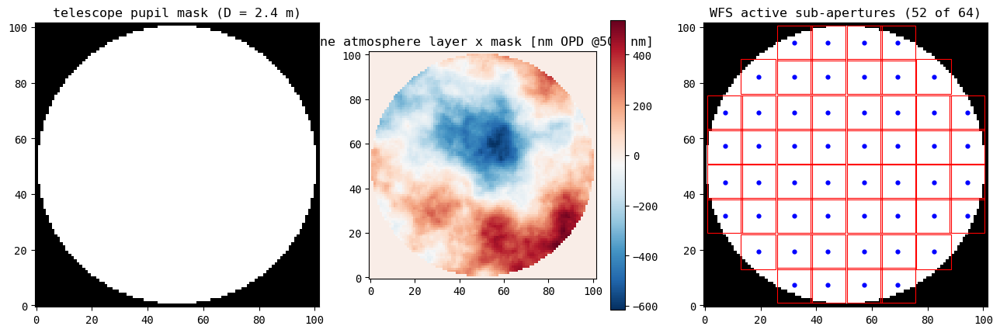

In [6]:
# --- 1.2b First look at the built system: pupil, one layer, WFS geometry ---
from matplotlib.patches import Rectangle   # sub-aperture boxes on ax[2]
scrns = sim.atmos.moveScrns()   # one frozen-flow step

print('phase screens:', scrns.shape, '-> units: nm')
print(f'layer 0 rms over the screen: {scrns[0].std():.1f} nm')

wfs = sim.wfss[0]
cx, cy = subap_centres(sim, wfs)   # sub-aperture centres in the sim-array frame: (col, row)
sp = sim.config.sim.pupilSize / wfs.nx_subaps   # sub-aperture size [px] across the pupil

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
ax[0].imshow(sim.mask, cmap='gray')
ax[0].set_title(f'telescope pupil mask (D = {sim.config.tel.telDiam} m)')
im = ax[1].imshow(crop_to_pupil(scrns[0], sim) * sim.mask, cmap='RdBu_r')
ax[1].set_title('one atmosphere layer x mask [nm OPD @500 nm]'); fig.colorbar(im, ax=ax[1])
ax[2].imshow(sim.mask, cmap='gray')
for x, y in zip(cx, cy):   # one box per active sub-aperture, at the true subap size
    ax[2].add_patch(Rectangle((x - sp/2, y - sp/2), sp, sp, fill=False, edgecolor='r', lw=0.8))
ax[2].scatter(cx, cy, c='b', s=12)   # imshow: horizontal = col, vertical = row
ax[2].set_title(f'WFS active sub-apertures ({wfs.n_subaps} of {wfs.nx_subaps**2})')
plt.tight_layout()


### 1.3 Stepping frame by frame

Our AO simulation works step-by-step executing `loopFrame()` for a number of iterations defined by `nIters`; 



> `loopFrame()` / `reset_loop()` need `makeIMat()` first — pre-calibration we step the pieces by hand (below).


frame 0:  inst Strehl = 0.252, WFE = 215 nm
frame 1:  inst Strehl = 0.291, WFE = 208 nm
frame 2:  inst Strehl = 0.325, WFE = 203 nm
WFS data per frame: 104 = 2 x 52 subaps
slope layout    : slopes[:n_subaps] = x-slopes, slopes[n_subaps:] = y-slopes [subap px]
screen units    : sim.scrns in nm OPD @500 nm, layer-0 rms = 236.0 nm


Text(0.5, 1.0, 'Instantaneous PSF')

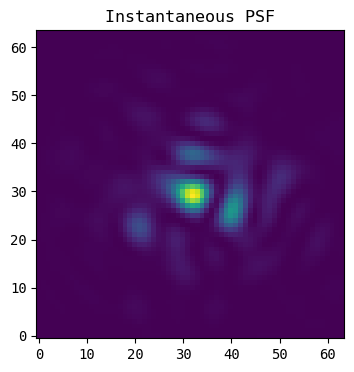

In [7]:
# --- 1.3 Stepping a frame by hand (before calibration) ---------------------
# loopFrame()/reset_loop() need makeIMat() first (runDM uses dm.n_valid_actuators,
# DM.reset() uses dm.dm_shape) — so pre-calibration we step the pieces manually:
# moveScrns -> runWfs -> runSciCams. (No reset needed: aoinit zeroed the buffers.)
n_iters = 3
for i in range(n_iters):
    sim.scrns = sim.atmos.moveScrns()                      # advance the frozen flow
    sim.slopes = sim.runWfs(scrns=sim.scrns, loopIter=i)   # WFS sees the full turbulence (no DM shape)
    sim.runSciCams(dmShape=None)                           # science camera, open loop
    
    print(f'frame {i}:  ' #slopes[:4] = {np.round(sim.slopes[:4], 3)} px,
          f'inst Strehl = {sim.sciCams[0].instStrehl:.3f}, '
          f'WFE = {sim.sciCams[0].calc_wavefronterror():.0f} nm')
    
print('WFS data per frame:', sim.config.sim.totalWfsData, '= 2 x', sim.wfss[0].n_subaps, 'subaps')
print('slope layout    : slopes[:n_subaps] = x-slopes, slopes[n_subaps:] = y-slopes [subap px]')
print('screen units    : sim.scrns in nm OPD @500 nm, layer-0 rms =', round(float(sim.scrns[0].std()), 1), 'nm')


plt.figure()
plt.imshow(sim.sciCams[0].detector)
plt.title('Instantaneous PSF')
# The long-exposure PSF is given by sim.sciImgs[0]


### Exercise 1 — configuration & initialisation
1. Change the `obsDiam = 0` in the configuration (either change in the yaml config file or change it directly in Python) then re-run cells. How many active sub-apertures are there left? (look at the display of the WFS and the `wfs.n_subaps` )
2. if the delay between two frames is 2.5ms (`loopTime = 2.5 ms`), by how many meters does each layer move ? Compare that to the size of you subapertures 


---
# Section 2 — Open loop (~15 min)
Here, by "open-loop" we mean not applying any correction. 
We do this simply by setting the gain of our control loop to zero (dm.gain = 0)

That means the WFS will measure the **full turbulence**, and the camera will be **seeing-limited PSF** (core+halo, Part 1 §5). 

We will do:
- initialize the `open_sim` object
- initialize our AO system
- compute the interaction matrix with `makeIMat()` (we don't need it yet; but it is required before running aoloop())
- run `aoloop` which will execute `loopFrames()` for several iterations `n_iters` (this can take some time if n_iters is large)

Once aoloop is finished, we can examine the results by looking at the attributes: 
`allSlopes`, `sciPhase[0]`, `sciImgsInst[0]`/`sciImgs[0]`, `instStrehl`/`longStrehl`, `WFE`, `ee50d`.


In [8]:
# --- 2.1 Open-loop run of the reference system ----------------------------
open_sim = soapy.Sim(soapy_conf('sh_8x8.yaml'))
open_sim.config.sim.simName  = None
open_sim.config.sim.logfile  = None
open_sim.config.sim.verbosity = 0
open_sim.config.sim.nIters   = 300
open_sim.config.atmos.randomSeed = 10


open_sim.aoinit()
open_sim.makeIMat(forceNew=True)   # required before any loop frame: runDM needs dm.n_valid_actuators
for dm in open_sim.config.dms:
    dm.gain = 0.0                  # gain 0 -> DMs apply nothing: pure open loop
open_sim.aoloop()

n_open = open_sim.config.sim.nIters
print('----- Results -------')
print('open-loop results over', n_open, 'frames:')
print(f'  long-exposure Strehl : {open_sim.longStrehl[0, -1]:.3f}')
print(f'  EE50 diameter        : {open_sim.ee50d[0]*1000:.1f} mas')
print(f'  WFE (last frame)     : {open_sim.WFE[0, -1]:.0f} nm rms')


config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
300 of 300: sh_8x8  Strehl -- sci_0: inst 0.12, long 0.07 


Science Camera 0: Long Exposure Strehl Ratio: 0.07
                  EE50 diameter [mas]: 429


Time moving atmosphere: 0.27
Time making IMats and CMats: 0.32
Time in WFS: 0.35
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.07
Time making science image: 1.00


----- Results -------
open-loop results over 300 frames:
  long-exposure Strehl : 0.067
  EE50 diameter        : 429.1 mas
  WFE (last frame)     : 288 nm rms


open-loop WFE: mean 398 nm rms over the pupil 
The rms WFE value fluctuates as a function of time as the phase screens translate


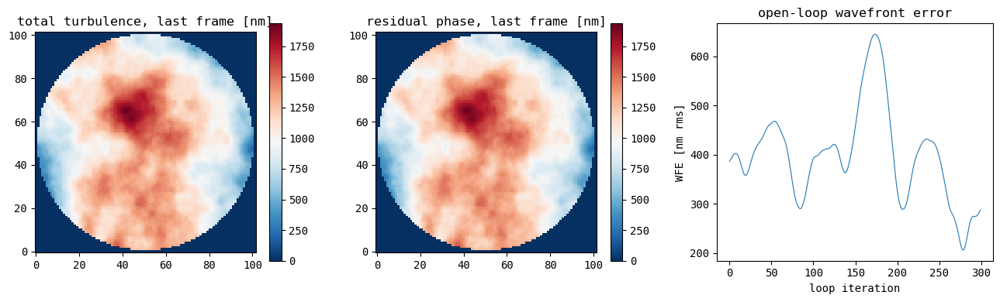

In [9]:
# --- 2.2 Open loop: turbulence, residual phase, WFE time series -----------
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
im = ax[0].imshow(crop_to_pupil(open_sim.scrns.sum(0), open_sim) * open_sim.mask, cmap='RdBu_r')
ax[0].set_title('total turbulence, last frame [nm]'); fig.colorbar(im, ax=ax[0])

im = ax[1].imshow(open_sim.sciPhase[0][-1], cmap='RdBu_r')
ax[1].set_title('residual phase, last frame [nm]'); fig.colorbar(im, ax=ax[1])

ax[2].plot(open_sim.WFE[0], lw=0.8)
ax[2].set_xlabel('loop iteration'); ax[2].set_ylabel('WFE [nm rms]')
ax[2].set_title('open-loop wavefront error')
plt.tight_layout()
print(f'open-loop WFE: mean {open_sim.WFE[0].mean():.0f} nm rms over the pupil ')
print(f'The rms WFE value fluctuates as a function of time as the phase screens translate')


subap FOV = 2.5 arcsec over 10 px -> 0.250 arcsec/px
slope rms (x+y combined): 0.160 arcsec


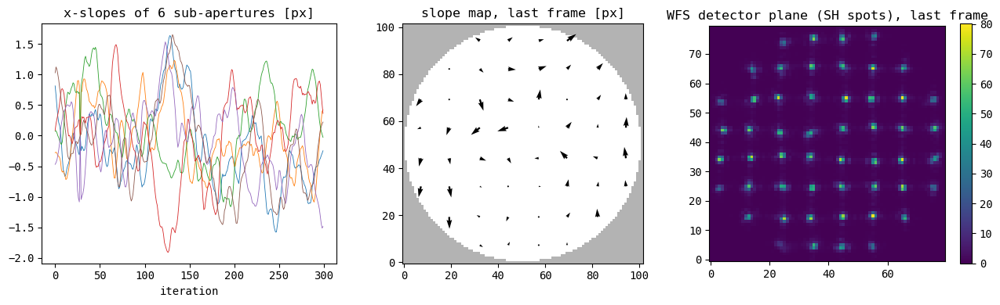

In [10]:
# --- 2.3 Open loop: WFS slopes and spot pattern ---------------------------
wfs = open_sim.wfss[0]
n_sub = wfs.n_subaps
slopes = open_sim.allSlopes                    # (nIters, 2*n_subaps) [subap px]
cx, cy = subap_centres(open_sim, wfs)   # (col, row) centres in the sim-array frame

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(slopes[:, :6], lw=0.6)
ax[0].set_title('x-slopes of 6 sub-apertures [px]'); ax[0].set_xlabel('iteration')

ax[1].imshow(open_sim.mask, cmap='gray', alpha=0.3)
ax[1].quiver(cx, cy, slopes[-1, n_sub:], slopes[-1, :n_sub], angles='xy', scale=30)   # U = slope along col, V = along row
ax[1].set_title('slope map, last frame [px]')

im = ax[2].imshow(wfs.wfsDetectorPlane, cmap='viridis')
ax[2].set_title('WFS detector plane (SH spots), last frame'); fig.colorbar(im, ax=ax[2])
plt.tight_layout()

slope_arcsec = slopes * wfs.pixel_scale        # px -> arcsec
print(f'subap FOV = {wfs.subap_fov} arcsec over {wfs.nx_subap_pixels} px -> {wfs.pixel_scale:.3f} arcsec/px')
print(f'slope rms (x+y combined): {np.sqrt((slope_arcsec**2).mean()):.3f} arcsec')


science lambda = 1.00 um, D = 2.4 m  ->  lambda/D = 86 mas
seeing 0.98*lambda/r0 = 550 mas at 1.00 um  (r0 = 0.37 m at that wavelength)
measured EE50 diameter = 429 mas   |   long-exposure Strehl = 0.067


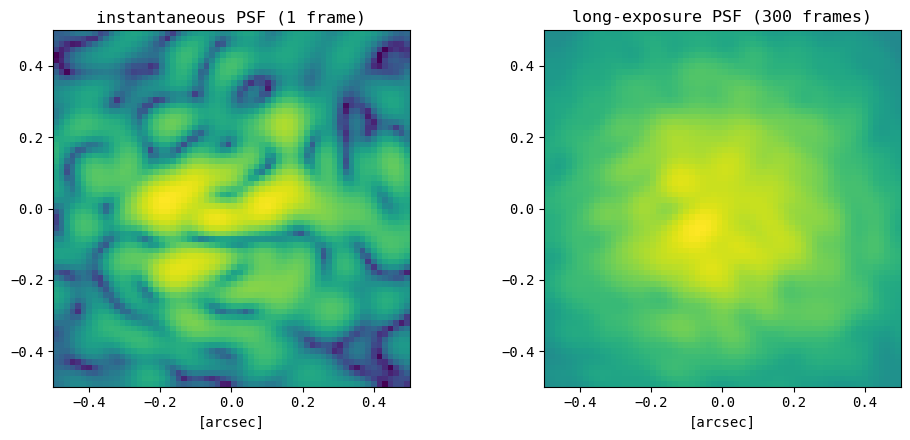

In [11]:
# --- 2.4 Open-loop science PSF: core + halo, EE50 vs seeing -----------------
sci = open_sim.sciCams[0]

pxl = sci.fov / sci.nx_pixels                  # pixel scale [arcsec/px]= field-of-view / number of pixels
ext = sci.nx_pixels / 2 * pxl
lam = open_sim.config.scis[0].wavelength
D   = open_sim.config.tel.telDiam
r0_500 = open_sim.config.atmos.r0

# instantaneous and long-exposure PSFs
psf_inst = open_sim.sciImgsInst[0][-1]
psf_long = open_sim.sciImgs[0]

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, (im, t) in enumerate([(psf_inst, 'instantaneous PSF (1 frame)'),
                             (psf_long, f'long-exposure PSF ({n_open} frames)')]):
    ax[a].imshow(logim(im / im.max()), extent=[-ext, ext, -ext, ext], vmin=-4, vmax=0)
    ax[a].set_title(t)
    ax[a].set_xlabel('[arcsec]')
plt.tight_layout()

# seeing expected at the SCIENCE wavelength: r0 scales as lambda^(6/5)
r0_lam = r0_500 * (lam / 500e-9) ** (6/5)
seeing = aotools.r0_to_seeing(r0_lam, lamda=lam)      # arcsec
print(f'science lambda = {lam*1e6:.2f} um, D = {D} m  ->  lambda/D = {lam/D*206265*1000:.0f} mas')
print(f'seeing 0.98*lambda/r0 = {seeing*1000:.0f} mas at {lam*1e6:.2f} um  (r0 = {r0_lam:.2f} m at that wavelength)')
print(f'measured EE50 diameter = {open_sim.ee50d[0]*1000:.0f} mas   |   long-exposure Strehl = {open_sim.longStrehl[0,-1]:.3f}')


### Exercise 2 — open loop
1. Compare the open-loop WFE vs the theoretical value (as derived by Noll, $\sigma_{OPD} = \sqrt{1.03\,(D/r_0)^{5/3}}\,\lambda/2\pi$. They don't match very well. Can you explain why? (hint: see the `aotools_lab.ipynb` notebook)
2. Off-axis GS (`GSPosition = [20, 0]`): anisoplanatism — WFE increase?
3. Faint GS (`GSMag = 14`, `photonNoise = True`): slopes and PSF?
4. Use `aotools.r0_from_slopes` to compute the Fried parameter from slopes. 


---
# Section 3 — Calibration: pokes → control matrix (~20 min)

`makeIMat()` per DM: 
Compute the **interaction matrix** IM with dimensions [n_valid_acts, n_slopes])

The IM gives the WFS response for a normalized commend (actuator poke or mode).
We acquire it by disabling the atmosphere an pushing each actuators to reasonable value (should be large to be above noise, but small to be in linear range).

Once we have the interaction matrix, we can compute the **reconstructor** (or control matrix) by inverting the IM: `R = pinv(D, rcond=svdConditioning)` (truncated SVD cuts noise-amplifying modes). 

With the reconstructor we can compute the DM commands: `commands = R.T @ slopes` (this ignores control).


conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
DM1 (FastPiezo): 81 poke shapes (8, 102, 102) [nm], iMatValue = 500.0 nm


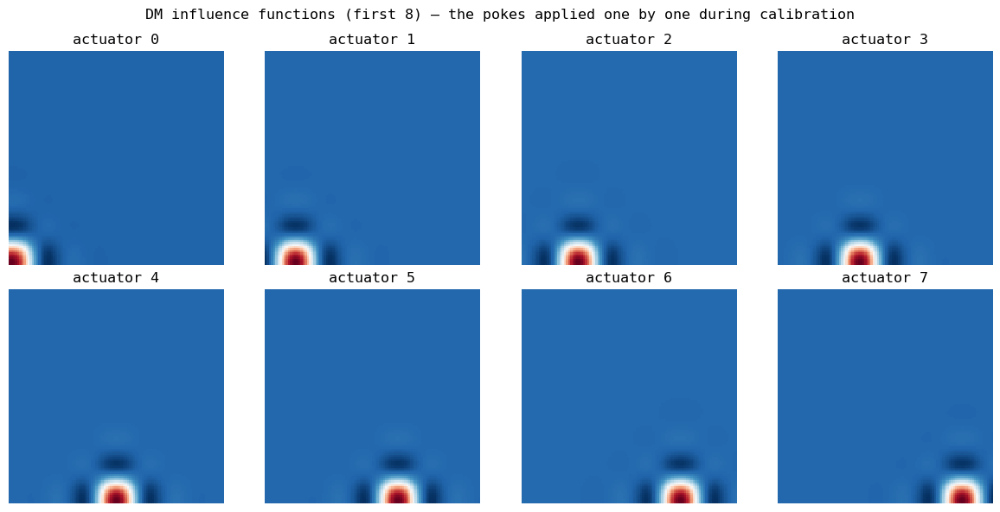

In [12]:
# Re-initialise (only mandatory if config has changed)
print(conf_file)
# config = soapy.loadSoapyConfig(conf_file)

sim = soapy.Sim(conf_file)
sim.config.sim.verbosity=1 # disabling verbose
sim.aoinit()

sim.makeIMat(forceNew=True)     # necessary 
# Pushing each DM actuators to visualise their influence functions 
# — the shapes pushed during calibration.
dm = sim.dms[1]
n_show = min(8, dm.n_valid_actuators)
shapes = np.zeros((n_show, sim.config.sim.scrnSize, sim.config.sim.scrnSize))
for k in range(n_show):
    cmd = np.zeros(dm.n_valid_actuators); 
    cmd[k] = 1.0
    shapes[k] = dm.dmFrame(cmd)     # poke shape [nm], includes iMatValue

print(f'DM1 ({type(dm).__name__}): {dm.n_valid_actuators} poke shapes {shapes.shape} [nm], '
      f'iMatValue = {dm.dmConfig.iMatValue} nm')

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k, a in enumerate(ax.flat):
    a.imshow(crop_to_pupil(shapes[k], sim), cmap='RdBu_r')
    a.set_title(f'actuator {k}'); a.axis('off')
fig.suptitle('DM influence functions (first 8) — the pokes applied one by one during calibration')
plt.tight_layout()


2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
interaction matrix IM: (83, 104)  (valid actuators x WFS measurements)
control matrix    R: (104, 83)  (WFS measurements x valid actuators), R = pinv(IM, rcond=0.03)
build time: 0.3 s
DM 0: 2 actuators, 2 valid after calibration
DM 1: 81 actuators, 81 valid after calibration
67 of 83 singular values kept at svdConditioning = 0.03


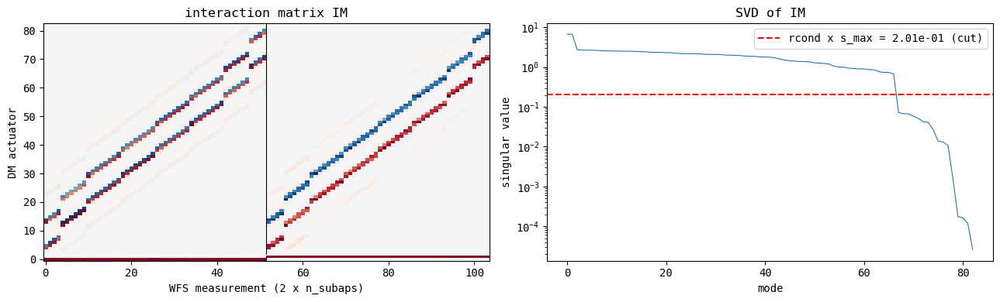

In [13]:
# --- 3.1 Calibration: build the interaction and control matrices -----------
sim.makeIMat(forceNew=True)     # simName=None -> nothing is loaded from disk

imat = sim.recon.interaction_matrix     # (n_valid_acts, n_measurements)
cmat = sim.recon.control_matrix         # (n_measurements, n_valid_acts)

print(f'interaction matrix IM: {imat.shape}  (valid actuators x WFS measurements)')
print(f'control matrix    R: {cmat.shape}  (WFS measurements x valid actuators), '
      f'R = pinv(IM, rcond={sim.config.recon.svdConditioning})')
print(f'build time: {sim.Timat:.1f} s')
for d, dm in sim.dms.items():
    print(f'DM {d}: {dm.n_acts} actuators, {dm.n_valid_actuators} valid after calibration')


# --- 3.2 Structure of IM and the SVD conditioning ---------------------------
wfs = sim.wfss[0]
n_sub = wfs.n_subaps
cx, cy = subap_centres(sim, wfs)   # (col, row) centres in the sim-array frame

s = np.linalg.svd(imat, compute_uv=False)
rcond = sim.config.recon.svdConditioning
n_kept = int((s > rcond * s.max()).sum())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].imshow(imat, aspect='auto', cmap='RdBu_r')
ax[0].axvline(n_sub - 0.5, color='k', lw=0.8)                     # x-slopes | y-slopes
if len(sim.dmAct1) > 1:
    ax[0].axhline(sim.dmAct1[1] - 0.5, color='w', lw=0.8)         # DM 0 (TT) rows | DM 1 rows
ax[0].set_xlabel('WFS measurement (2 x n_subaps)'); ax[0].set_ylabel('DM actuator')
ax[0].set_title('interaction matrix IM')

# mid = imat.shape[0] // 2
# ax[1].imshow(sim.mask, cmap='gray', alpha=0.3)
# ax[1].quiver(cx, cy, imat[mid, n_sub:], imat[mid, :n_sub], angles='xy', scale=2)   # U = slope along col, V = along row
# ax[1].set_title(f'slope response to poking actuator {mid}')

ax[1].semilogy(s, lw=0.8)
ax[1].axhline(rcond * s.max(), color='r', ls='--',
              label=f'rcond x s_max = {rcond*s.max():.2e} (cut)')
ax[1].set_xlabel('mode')
ax[1].set_ylabel('singular value')
ax[1].legend()
ax[1].set_title('SVD of IM')
plt.tight_layout()

print(f'{n_kept} of {len(s)} singular values kept at svdConditioning = {rcond}')


### 3.3 Video of the interaction matrix acquisition

For-loop poking individual actuators (`dm.dmFrame`) and recording a WFS image `sim.runWfs`.

Each **column of IM** is the slope vector computed from one WFS image.


In [14]:
# --- 3.4 Video of the calibration: every poke -> WFS spot image --------------
# Re-run the pokes one by one (atmosphere off), recording the WFS detector plane.
from matplotlib import animation
from IPython.display import HTML, display

os.makedirs('videos', exist_ok=True)
dm = sim.dms[1]; wfs = sim.wfss[0]
sim.scrns = sim.atmos.moveScrns() # necessary to make sure sim.scrns exist
zero_scrns = np.zeros_like(sim.scrns)
n_pokes = dm.n_valid_actuators
wfs.zeroData()   # clear detector + focal-plane accumulators left over from earlier runs

poke_shapes, poke_wfs = [], []
for k in tqdm(range(n_pokes)):
    cmd = np.zeros(n_pokes); cmd[k] = 1.0
    shape = dm.dmFrame(cmd)
    # runWfs expects dmShape as one plane per DM — the (nDM, scrnSize, scrnSize)
    dmShape = np.zeros_like(sim.closed_correction)
    dmShape[1] = shape   # poke on DM 1, TT (DM 0) flat
    wfs.frame(zero_scrns, dmShape, read=True)   # runWfs(loopIter=0) reads only on the 1st call (wfsFrameNo), then read=False and wfsDetectorPlane accumulates
    poke_shapes.append(crop_to_pupil(shape, sim) * sim.mask)
    poke_wfs.append(wfs.wfsDetectorPlane.copy())

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
im0 = ax[0].imshow(poke_shapes[20], cmap='RdBu_r')
ax[0].set_title('DM poke shape [nm]')
im1 = ax[1].imshow(poke_wfs[20], cmap='viridis')
ax[1].set_title('WFS detector plane')
fig.suptitle('calibration poke 20')

def update(k):
    im0.set_data(poke_shapes[k]);
    im1.set_data(poke_wfs[k])
    fig.suptitle(f'calibration: poking actuator {k+1}/{n_pokes} — the spots shift in the WFS')
    return im0, im1

anim = animation.FuncAnimation(fig, update, frames=n_pokes, interval=100, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))     # inline animation (VS Code / Jupyter / Colab)

try:
    anim.save('videos/imat_pokes.mp4', writer='ffmpeg', fps=10, dpi=110)
    print('saved videos/imat_pokes.mp4')
except Exception as e:
    print('mp4 save skipped (is ffmpeg installed?):', e)


100%|██████████| 81/81 [00:00<00:00, 871.83it/s]


saved videos/imat_pokes.mp4


### Exercise 3 — calibration
1. Change the `iMatValue` (equivalent to the stroke apply to each actuators during IM acquisition): make it 10 times bigger or 10 times smaller. Which change do you observe?
2. Change the number of actuators DM  (`nxActuators` 9 → 17), and observe the changes


For later, when doing closed loop:
1. Change the `svdConditioning` when computing the reconstructor (e.g. 0.03 → 0.3). How does your closed-loop performance changes?


---
# Section 4 — Closed loop (~20 min)

Each new residual measurements in the "DM space": `commands = R.T @ slopes`.

Assuming a pure integrator, residual commands `gain * commands` are added to the DM after a delay given by `loopDelay` frames.

Run `aoloop()` on the calibrated `sim`: Strehl rises to a plateau, residual WFE drops by orders of magnitude.


500 of 500: sh_8x8  Strehl -- sci_0: inst 0.81, long 0.80 


Science Camera 0: Long Exposure Strehl Ratio: 0.80
                  EE50 diameter [mas]: 106


Time moving atmosphere: 0.41
Time making IMats and CMats: 0.29
Time in WFS: 0.56
	 of which time spent in : 0.00
Time in Reconstruction: 0.01
Time in DM: 0.10
Time making science image: 1.54


closed-loop long-exposure Strehl (last frame): 0.796
closed-loop WFE (last frame)                : 86 nm rms
closed-loop EE50 diameter                   : 106.3 mas
timings: iMat 0.3s | atmos 0.4s | WFS 0.6s | recon 0.0s | DM 0.1s | sci 1.5s


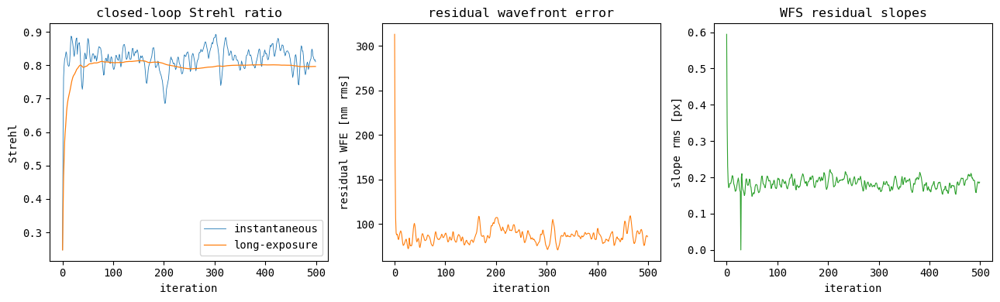

In [15]:
# --- 4.1 Closed-loop run and convergence -----------------------------------
sim.reset_loop()        # zero the buffers, keep the calibration
sim.aoloop()

iters = np.arange(sim.config.sim.nIters)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(iters, sim.instStrehl[0], lw=0.6, label='instantaneous')
ax[0].plot(iters, sim.longStrehl[0], lw=0.9, label='long-exposure')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('Strehl'); ax[0].legend()
ax[0].set_title('closed-loop Strehl ratio')
ax[1].plot(iters, sim.WFE[0], lw=0.8, color='C1')
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('residual WFE [nm rms]')
ax[1].set_title('residual wavefront error')
ax[2].plot(iters, np.sqrt((sim.allSlopes**2).mean(1)), lw=0.8, color='C2')
ax[2].set_xlabel('iteration'); ax[2].set_ylabel('slope rms [px]')
ax[2].set_title('WFS residual slopes')
plt.tight_layout()

print(f'closed-loop long-exposure Strehl (last frame): {sim.longStrehl[0,-1]:.3f}')
print(f'closed-loop WFE (last frame)                : {sim.WFE[0,-1]:.0f} nm rms')
print(f'closed-loop EE50 diameter                   : {sim.ee50d[0]*1000:.1f} mas')
print(f'timings: iMat {sim.Timat:.1f}s | atmos {sim.Tatmos:.1f}s | WFS {sim.Twfs:.1f}s | '
      f'recon {sim.recon.Trecon:.1f}s | DM {sim.Tdm:.1f}s | sci {sim.Tsci:.1f}s')


Strehl : open 0.067  ->  closed 0.796
WFE    : open 288 nm  ->  closed 86 nm rms
EE50   : open 429 mas  ->  closed 106 mas


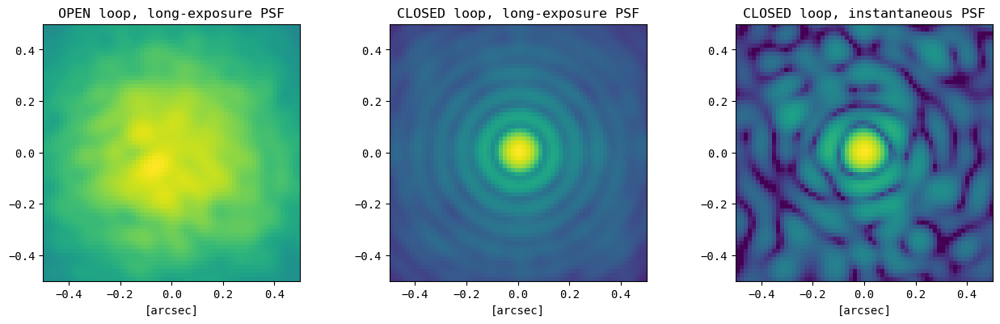

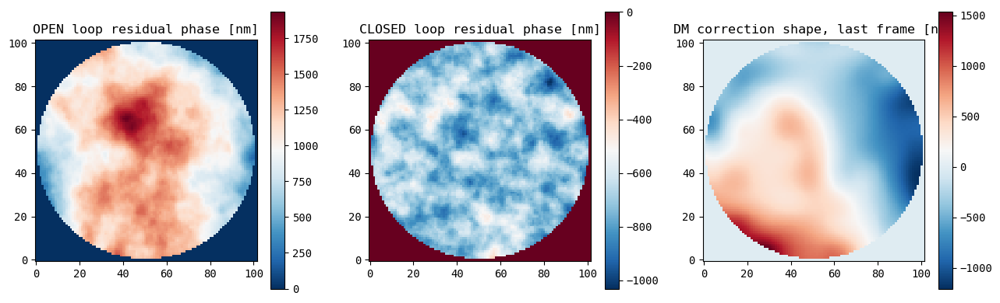

In [16]:
# --- 4.2 Open loop vs closed loop ------------------------------------------
sci = sim.sciCams[0]
pxl = sci.fov / sci.nx_pixels
ext = sci.nx_pixels / 2 * pxl

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (im, t) in enumerate([(open_sim.sciImgs[0], 'OPEN loop, long-exposure PSF'),
                             (sim.sciImgs[0], 'CLOSED loop, long-exposure PSF'),
                             (sim.sciImgsInst[0][-1], 'CLOSED loop, instantaneous PSF')]):
    ax[a].imshow(logim(im / im.max()), extent=[-ext, ext, -ext, ext], vmin=-4, vmax=0)
    ax[a].set_title(t); ax[a].set_xlabel('[arcsec]')
plt.tight_layout()

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
im = ax[0].imshow(open_sim.sciPhase[0][-1], cmap='RdBu_r'); fig.colorbar(im, ax=ax[0])
ax[0].set_title('OPEN loop residual phase [nm]')
im = ax[1].imshow(sim.sciPhase[0][-1], cmap='RdBu_r'); fig.colorbar(im, ax=ax[1])
ax[1].set_title('CLOSED loop residual phase [nm]')
im = ax[2].imshow(crop_to_pupil(sim.combinedCorrection.sum(0), sim) * sim.mask, cmap='RdBu_r')
fig.colorbar(im, ax=ax[2])
ax[2].set_title('DM correction shape, last frame [nm]')
plt.tight_layout()

print(f'Strehl : open {open_sim.longStrehl[0,-1]:.3f}  ->  closed {sim.longStrehl[0,-1]:.3f}')
print(f'WFE    : open {open_sim.WFE[0,-1]:.0f} nm  ->  closed {sim.WFE[0,-1]:.0f} nm rms')
print(f'EE50   : open {open_sim.ee50d[0]*1000:.0f} mas  ->  closed {sim.ee50d[0]*1000:.0f} mas')


### 4.2b Watch the loop run — video

Per loop frame (closed loop): WFS detector plane, DM shape, instantaneous PSF — inline below, saved to `videos/closed_loop.mp4`.


In [17]:
# --- 4.2b Loop video: WFS spots | DM shape | instantaneous PSF ---------------
from matplotlib import animation
from IPython.display import HTML, display

os.makedirs('videos', exist_ok=True)
sim.reset_loop()                 # zero the buffers, keep the calibration
n_frames = 120
wfs_f, dm_f, psf_f = [], [], []
for i in tqdm(range(n_frames)):
    sim.loopFrame()
    wfs_f.append(sim.wfss[0].wfsDetectorPlane.copy())
    dm_f.append(crop_to_pupil(sim.combinedCorrection.sum(0), sim) * sim.mask)
    psf_f.append(logim(sim.sciCams[0].detector))    # log10 of the instantaneous PSF

psf_max = max(f.max() for f in psf_f)
dm_absmax = max(np.abs(f).max() for f in dm_f)   # fixed symmetric nm scale for the DM panel
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
im0 = ax[0].imshow(wfs_f[0], cmap='viridis');                       ax[0].set_title('WFS detector plane')
# set_data() does NOT re-autoscale the colour norm, and dm_f[0] is all zeros after
# reset_loop() (vmin=vmax=0) -> without explicit vmin/vmax the DM panel stays flat.
im1 = ax[1].imshow(dm_f[0], cmap='RdBu_r', vmin=-dm_absmax, vmax=dm_absmax); ax[1].set_title('DM correction [nm]')
im2 = ax[2].imshow(psf_f[0] - psf_max, vmin=-4, vmax=0);            ax[2].set_title('instantaneous PSF (log10)')
fig.suptitle('frame 0')

def update(i):
    im0.set_data(wfs_f[i]); im1.set_data(dm_f[i]); im2.set_data(psf_f[i] - psf_max)
    fig.suptitle(f'closed loop, frame {i+1}/{n_frames} — inst Strehl {sim.instStrehl[0][i]:.2f}, '
                 f'WFE {sim.WFE[0][i]:.0f} nm')
    return im0, im1, im2

anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=100, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))

try:
    anim.save('videos/closed_loop.mp4', writer='ffmpeg', fps=10, dpi=110)
    print('saved videos/closed_loop.mp4')
except Exception as e:
    print('mp4 save skipped (is ffmpeg installed?):', e)


  0%|          | 0/120 [00:00<?, ?it/s]

18 of 500: sh_8x8  Strehl -- sci_0: inst 0.86, long 0.71 

 15%|█▌        | 18/120 [00:00<00:00, 172.35it/s]

36 of 500: sh_8x8  Strehl -- sci_0: inst 0.80, long 0.76 

 30%|███       | 36/120 [00:00<00:00, 162.69it/s]

54 of 500: sh_8x8  Strehl -- sci_0: inst 0.81, long 0.78 

... (6 outputs left out)

 91%|█████████ | 109/120 [00:00<00:00, 176.05it/s]

120 of 500: sh_8x8  Strehl -- sci_0: inst 0.76, long 0.78 

100%|██████████| 120/120 [00:00<00:00, 173.72it/s]


saved videos/closed_loop.mp4


### 4.3 Parameter study — gain, delay, seeing

- **gain** `dm.gain`: fraction of residual applied per frame — too low sluggish, too high (with delay) unstable;
- **delay** `loopDelay` [frames]: latency → temporal error;
- **seeing** `atmos.r0`: sets $(D/r_0)^{5/3}$ → fitting error.

Swept below in reproducible way (same `randomSeed` → identical atmosphere; ~30 s per run — lower `nIters` if slow).


  0%|          | 0/5 [00:00<?, ?it/s]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.58, long 0.55 


Science Camera 0: Long Exposure Strehl Ratio: 0.55
                  EE50 diameter [mas]: 161


Time moving atmosphere: 0.21
Time making IMats and CMats: 0.14
Time in WFS: 0.28
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.06
Time making science image: 0.78




 20%|██        | 1/5 [00:01<00:07,  1.89s/it]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.80, long 0.75 


Science Camera 0: Long Exposure Strehl Ratio: 0.75
                  EE50 diameter [mas]: 114


Time moving atmosphere: 0.21
Time making IMats and CMats: 0.13
Time in WFS: 0.28
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.77




 40%|████      | 2/5 [00:03<00:05,  1.88s/it]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.84, long 0.81 


Science Camera 0: Long Exposure Strehl Ratio: 0.81
                  EE50 diameter [mas]: 106


Time moving atmosphere: 0.20
Time making IMats and CMats: 0.14
Time in WFS: 0.28
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.77




... (10 outputs left out)

 75%|███████▌  | 3/4 [00:05<00:01,  1.83s/it]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.04, long 0.04 


Science Camera 0: Long Exposure Strehl Ratio: 0.04
                  EE50 diameter [mas]: nan


Time moving atmosphere: 0.19
Time making IMats and CMats: 0.14
Time in WFS: 0.28
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.76




100%|██████████| 4/4 [00:07<00:00,  1.83s/it]


 gain | Strehl | WFE [nm]
  0.2 |  0.552 |     134
  0.4 |  0.753 |      88
  0.6 |  0.810 |      76
  0.8 |  0.831 |      71
  1.0 |  0.841 |      69
 delay | Strehl | WFE [nm]
   0   |  0.810 |      76
   1   |  0.768 |      85
   2   |  0.391 |     179
   3   |  0.044 |     582


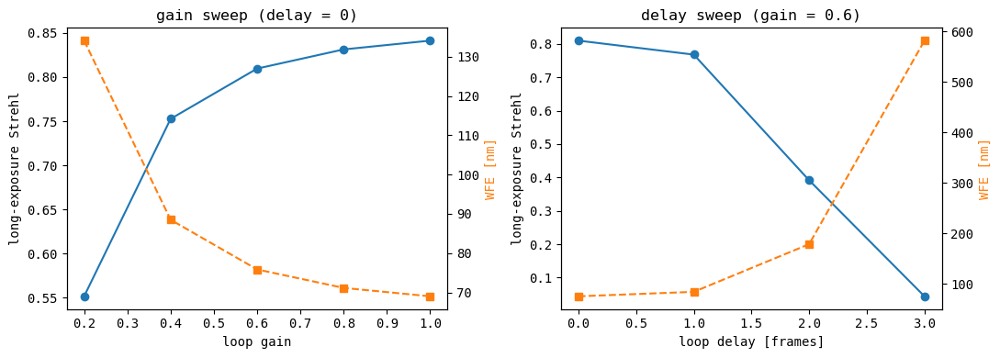

In [18]:
# --- 4.3 Sweep loop gain and loop delay (fresh reproducible sim per point) --
def run_sim(gain=None, loopDelay=None, r0=None, nIters=250):
    # Fresh closed-loop run of sh_8x8.yaml with overrides; returns the sim object.
    s = soapy.Sim(soapy_conf('sh_8x8.yaml'))
    s.config.sim.simName = None
    s.config.sim.logfile = None
    s.config.sim.verbosity = 0
    s.config.sim.nIters = nIters
    s.config.atmos.randomSeed = 0          # same atmosphere for every run

    if gain is not None:
        for dm in s.config.dms:            # loop gain is per-DM (applied in recon.apply_gain)
            dm.gain = gain
    if loopDelay is not None:
        s.config.sim.loopDelay = loopDelay
    if r0 is not None:
        s.config.atmos.r0 = r0
    s.aoinit()
    s.makeIMat(forceNew=True)
    s.aoloop()
    return s

# gain sweep at zero delay
gains = [0.2, 0.4, 0.6, 0.8, 1.0]
strehl_g, wfe_g = [], []
for g in tqdm(gains):
    s = run_sim(gain=g)
    strehl_g.append(s.longStrehl[0, -1])
    wfe_g.append(s.WFE[0, -1])

# delay sweep at gain 0.6
delays = [0, 1, 2, 3]
strehl_d, wfe_d = [], []
for dl in tqdm(delays):
    s = run_sim(gain=0.6, loopDelay=dl)
    strehl_d.append(s.longStrehl[0, -1])
    wfe_d.append(s.WFE[0, -1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(gains, strehl_g, 'o-', label='Strehl')
ax[0].set_xlabel('loop gain'); ax[0].set_ylabel('long-exposure Strehl'); ax[0].set_title('gain sweep (delay = 0)')
ax0b = ax[0].twinx(); ax0b.plot(gains, wfe_g, 's--', color='C1'); ax0b.set_ylabel('WFE [nm]', color='C1')
ax[1].plot(delays, strehl_d, 'o-', label='Strehl')
ax[1].set_xlabel('loop delay [frames]'); ax[1].set_ylabel('long-exposure Strehl'); ax[1].set_title('delay sweep (gain = 0.6)')
ax1b = ax[1].twinx(); ax1b.plot(delays, wfe_d, 's--', color='C1'); ax1b.set_ylabel('WFE [nm]', color='C1')
plt.tight_layout()

print(' gain | Strehl | WFE [nm]')
for g, st, wf in zip(gains, strehl_g, wfe_g):
    print(f'  {g:.1f} |  {st:.3f} | {wf:7.0f}')
print(' delay | Strehl | WFE [nm]')
for dl, st, wf in zip(delays, strehl_d, wfe_d):
    print(f'   {dl}   |  {st:.3f} | {wf:7.0f}')


### Exercise 4 — closed loop & error budgets
1. Copying the gain and delay sweep, do a sweep over different r0 and compare the performance (Strehl and WFE).
2. For a fixed r0, gain and delay, try to increase the number of actuators and see what happen (you might need to tune the interaction matrix acquisition/the svdConditioning).
3. Try a off-axis target (`position = [10, 0]`) to observe the effect of anisoplanatism (see also `aotools.isoplanaticAngle`)



# More advanced examples and exercises

### Exercise 5 — single-mode fiber coupling

A single-mode fiber accepts only its Gaussian mode → injected flux = **coupling efficiency** $\eta = |\sum \mathrm{fibre\_mode} \cdot E_{focal} \cdot \mathrm{mask}|^2$. 

In Soapy: `scis[0].type = 'singleModeFibre'` (`instStrehl` = η; `aoinit()` prints the diffraciton limited reference `refStrehl` ≈ 0.8 (Airy pattern is differn than the Gaussian mode of the fiber).

1. Open vs closed (below): mean η vs §4 Strehl; η_closed ≈ Strehl × η_ref?
2. Why η < 1 even for a perfect PSF? (mode mismatch; circular-pupil optimum ≈ 0.81)
3. Misalignment (target `[2, 0]` arcsec, static TT): how fast does η drop?


<>:27: SyntaxWarning: invalid escape sequence '\e'
<>:27: SyntaxWarning: invalid escape sequence '\e'
/var/folders/y8/qwkl8q7s08l_x77m0b624hm40000gn/T/ipykernel_70368/1141343614.py:27: SyntaxWarning: invalid escape sequence '\e'
  ax[0].set_xlabel('iteration'); ax[0].set_ylabel('coupling efficiency $\eta$')


config found: conf/sh_8x8.yaml
Coupling efficiency: 0.814
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.00, long 0.00 


Science Camera 0: Long Exposure Strehl Ratio: 0.00
                  EE50 diameter [mas]: 461


Time moving atmosphere: 0.20
Time making IMats and CMats: 0.13
Time in WFS: 0.27
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.75


config found: conf/sh_8x8.yaml
Coupling efficiency: 0.814
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.65, long 0.00 


Science Camera 0: Long Exposure Strehl Ratio: 0.00
                  EE50 diameter [mas]: 106


Time moving atmosphere: 0.19
Time making IMats and CMats: 0.14
Time in WFS: 0.28
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.76


mean eta (after frame 50):

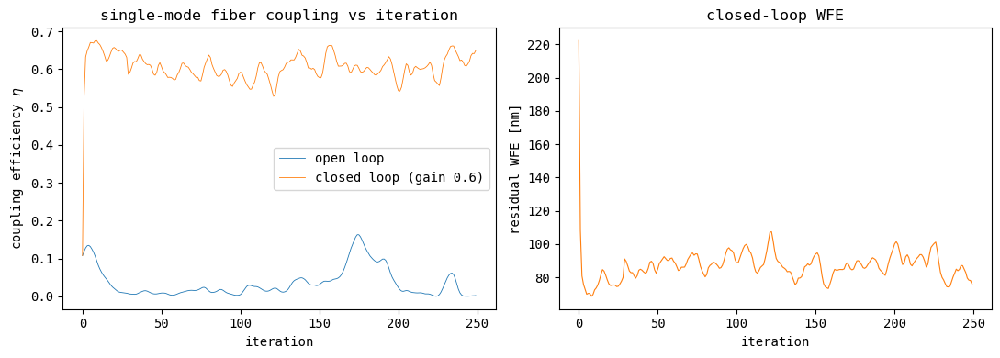

In [19]:
# --- Exercise 5 (optional): single-mode fiber coupling ---------------------
# singleModeFibre science camera: the reported instStrehl is the coupling
# efficiency eta = |<fibre_mode | E_focal>|^2 (Gaussian mode vs Airy PSF).
def run_fibre(gain, nIters=250):
    s = soapy.Sim(soapy_conf('sh_8x8.yaml'))
    s.config.sim.simName = None
    s.config.sim.logfile = None
    s.config.sim.verbosity = 0
    s.config.sim.nIters = nIters
    s.config.atmos.randomSeed = 0
    s.config.scis[0].type = 'singleModeFibre'   # fiber instead of PSF camera
    for dm in s.config.dms:
        dm.gain = gain
    s.aoinit()          # prints the diffraction-limited reference coupling
    s.makeIMat(forceNew=True)
    s.aoloop()
    return s

s_open   = run_fibre(gain=0.0)    # open loop
s_closed = run_fibre(gain=0.6)    # closed loop

eta_open, eta_closed = s_open.instStrehl[0], s_closed.instStrehl[0]
iters = np.arange(s_closed.config.sim.nIters)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(iters, eta_open, lw=0.6, label='open loop')
ax[0].plot(iters, eta_closed, lw=0.6, label='closed loop (gain 0.6)')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('coupling efficiency $\eta$')
ax[0].set_title('single-mode fiber coupling vs iteration'); ax[0].legend()
ax[1].plot(iters, s_closed.WFE[0], lw=0.8, color='C1')
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('residual WFE [nm]')
ax[1].set_title('closed-loop WFE')
plt.tight_layout()
print(f'mean eta (after frame 50): open {eta_open[50:].mean():.3f}  ->  closed {eta_closed[50:].mean():.3f}')
print(f'closed-loop residual WFE : {s_closed.WFE[0,-1]:.0f} nm rms')


### Exercise 6 — Pyramid WFS (`conf/pwfs.yaml`)

A **pyramid WFS** puts a 4-faced pyramid in the focal plane: the detector sees **4 pupil images**, the wavefront in their intensity differences; the beam is **modulated** on a circle (`nb_modulation` positions/frame) to linearise. soapy: `type: Pyramid`; `conf/pwfs.yaml` = standalone system (4 m, 20×20 subaps, PWFS + Zernike DM).

1. `wfs.wfsDetectorPlane` = the 4 pupils; poke one DM mode (as in 3.3): which brighten/darken?
2.  Compare performance for different modulation
3. Compare slope rms and closed-loop Strehl/WFE vs the Shack-Hartman system.


config found: conf/pwfs.yaml
WFS: type=Pyramid, nxSubaps=20, nb_modulation=32, amplitude_modulation=0.1 arcsec, pupil_separation=6 px
DM : type=Zernike, nxActuators=45 (Zernike modes)
45 of 45: Generating 45 Actuator DM iMat
60 of 60: pwfs  Strehl -- sci_0: inst 0.89, long 0.81 


Science Camera 0: Long Exposure Strehl Ratio: 0.81
                  EE50 diameter [mas]: 99


Time moving atmosphere: 0.18
Time making IMats and CMats: 1.78
Time in WFS: 2.27
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.17
Time making science image: 2.08


PWFS closed loop : long Strehl 0.813, WFE 176 nm rms, WFS time/frame 38 ms
SH reference (Sec 4): long Strehl 0.000, WFE 86 nm


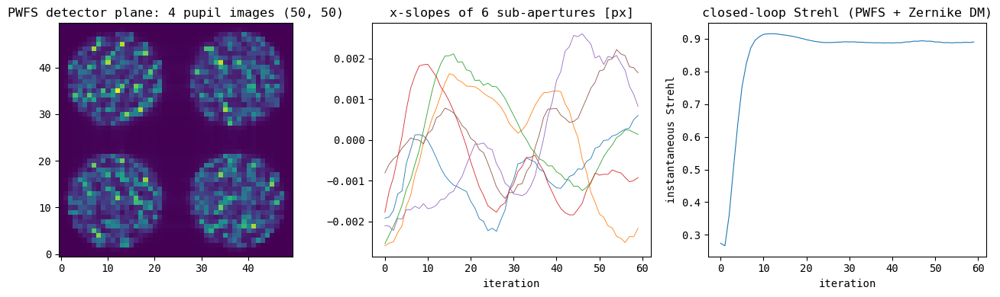

In [20]:
# --- Exercise 6: Pyramid WFS, standalone conf/pwfs.yaml ----------------------
psim = soapy.Sim(soapy_conf('pwfs.yaml'))
psim.config.sim.simName = None
psim.config.sim.logfile = None
psim.config.sim.verbosity = 0
psim.config.sim.nIters = 60
psim.config.atmos.randomSeed = 0
for f in ['saveSlopes', 'saveInstPsf', 'saveSciRes']:
    setattr(psim.config.sim, f, True)
psim.config.dms[0].nxActuators = 45     # fewer Zernike modes -> faster calibration

pw = psim.config.wfss[0]
print(f'WFS: type={pw.type}, nxSubaps={pw.nxSubaps}, nb_modulation={pw.nb_modulation}, '
      f'amplitude_modulation={pw.amplitude_modulation} arcsec, pupil_separation={pw.pupil_separation} px')
print(f'DM : type={psim.config.dms[0].type}, nxActuators={psim.config.dms[0].nxActuators} (Zernike modes)')

psim.aoinit()
psim.makeIMat(forceNew=True)
psim.aoloop()

wfs = psim.wfss[0]
iters = np.arange(psim.config.sim.nIters)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(wfs.wfsDetectorPlane, cmap='viridis')
ax[0].set_title(f'PWFS detector plane: 4 pupil images {wfs.wfsDetectorPlane.shape}')
ax[1].plot(iters, psim.allSlopes[:, :6], lw=0.6)
ax[1].set_title('x-slopes of 6 sub-apertures [px]'); ax[1].set_xlabel('iteration')
ax[2].plot(iters, psim.instStrehl[0], lw=0.8)
ax[2].set_xlabel('iteration'); ax[2].set_ylabel('instantaneous Strehl')
ax[2].set_title('closed-loop Strehl (PWFS + Zernike DM)')
plt.tight_layout()
print(f'PWFS closed loop : long Strehl {psim.longStrehl[0,-1]:.3f}, WFE {psim.WFE[0,-1]:.0f} nm rms, '
      f'WFS time/frame {psim.Twfs/psim.config.sim.nIters*1000:.0f} ms')
print(f'SH reference (Sec 4): long Strehl {sim.longStrehl[0,-1]:.3f}, WFE {sim.WFE[0,-1]:.0f} nm')


### Exercise 7 — modal DM: Zernike (worked) vs Karhunen–Loève (optional)

A **modal DM** is driven by orthogonal modes, not per-actuator pokes: `type: Zernike` or `KarhunenLoeve`, `nxActuators` = number of modes; influence functions in `dm.iMatShapes` (calibration unchanged).

1. Are their any modes dropped during initialiation/calibration (`n_valid_actuators` vs `nxActuators`)?
2. Closed-loop Strehl/WFE vs the 9×9 FastPiezo  at same `nIters`?
3. Optional: `run_modal('KarhunenLoeve')` — KL vs Zernike at the same mode count?


config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
45 of 45: Generating 45 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.70, long 0.69 


Science Camera 0: Long Exposure Strehl Ratio: 0.69
                  EE50 diameter [mas]: 122


Time moving atmosphere: 0.20
Time making IMats and CMats: 0.09
Time in WFS: 0.29
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.10
Time making science image: 0.77


DM1: Zernike, 45 modes, 45 valid after calibration
modal DM (Zernike, 45 modes): long Strehl 0.688, WFE 116 nm rms
reference FastPiezo 9x9 (Sec 4): long Strehl 0.000, WFE 86 nm


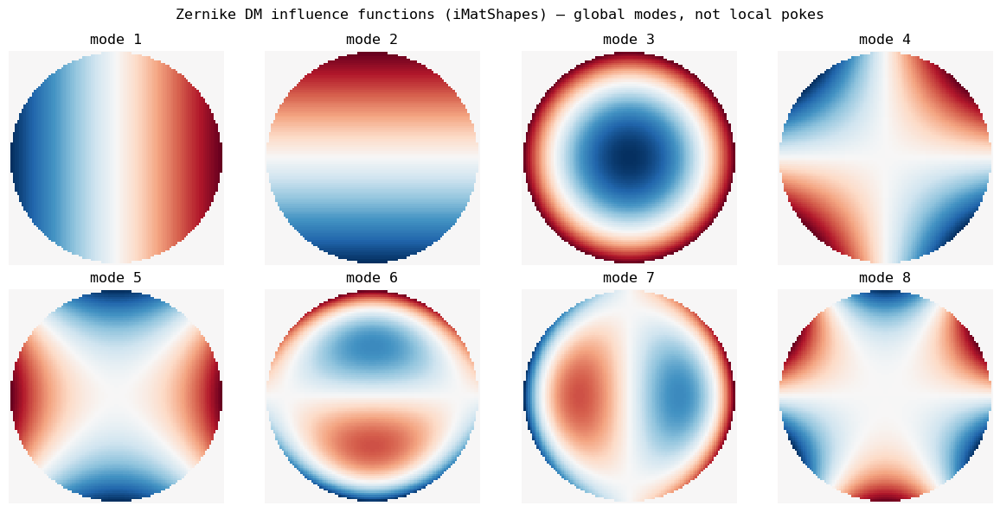

In [21]:
# --- Exercise 7: modal DM (Zernike worked, KarhunenLoeve optional) -----------
def run_modal(dm_type, n_modes=45, nIters=250):
    s = soapy.Sim(soapy_conf('sh_8x8.yaml'))
    s.config.sim.simName = None
    s.config.sim.logfile = None
    s.config.sim.verbosity = 0
    s.config.sim.nIters = nIters
    s.config.atmos.randomSeed = 0
    for f in ['saveSlopes', 'saveInstPsf', 'saveSciRes']:
        setattr(s.config.sim, f, True)
    s.config.dms[1].type = dm_type          # modal DM instead of FastPiezo
    s.config.dms[1].nxActuators = n_modes   # = number of modes
    s.aoinit()
    s.makeIMat(forceNew=True)
    s.aoloop()
    return s

s_mod = run_modal('Zernike', n_modes=45)

# modal DMs store their influence functions (unlike FastPiezo): show the first 8
dm = s_mod.dms[1]
print(f'DM1: {type(dm).__name__}, {dm.n_acts} modes, {dm.n_valid_actuators} valid after calibration')
shapes = dm.iMatShapes[:8]                  # (8, scrnSize, scrnSize)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k, a in enumerate(ax.flat):
    a.imshow(crop_to_pupil(shapes[k], s_mod), cmap='RdBu_r')
    a.set_title(f'mode {k+1}'); a.axis('off')
fig.suptitle('Zernike DM influence functions (iMatShapes) — global modes, not local pokes')
plt.tight_layout()

print(f'modal DM (Zernike, 45 modes): long Strehl {s_mod.longStrehl[0,-1]:.3f}, WFE {s_mod.WFE[0,-1]:.0f} nm rms')
print(f'reference FastPiezo 9x9 (Sec 4): long Strehl {sim.longStrehl[0,-1]:.3f}, WFE {sim.WFE[0,-1]:.0f} nm')

# optional: s_kl = run_modal('KarhunenLoeve', n_modes=45)   # then compare the same way


### Exercise 7b — video of the modal calibration

Same idea as §3.4, but for the modal DM of Exercise 7: each frame pokes one **Zernike mode** (atmosphere off, as in `makeIMat`) and shows the mode shape next to the WFS detector plane. Inline below, saved to `videos/modal_imat.mp4`.


In [22]:
# --- Exercise 7b: record the modal iMat — one Zernike mode per frame ---------
from matplotlib import animation
from IPython.display import HTML, display

os.makedirs('videos', exist_ok=True)
dm = s_mod.dms[1]
wfs = s_mod.wfss[0]
zero_scrns = np.zeros_like(s_mod.scrns)          # atmosphere off, as in makeIMat
n_modes = dm.n_valid_actuators
wfs.zeroData()   # same as 3.4: clear detector + FP accumulators

mode_shapes, mode_wfs = [], []
for k in tqdm(range(n_modes)):
    cmd = np.zeros(n_modes); cmd[k] = 1.0
    shape = dm.dmFrame(cmd)                       # mode shape [nm]
    dmShape = np.zeros_like(s_mod.closed_correction); dmShape[1] = shape   # per-DM stack, as in 3.3
    wfs.frame(zero_scrns, dmShape, read=True)   # same as 3.4: force read=True, else the detector accumulates
    mode_shapes.append(crop_to_pupil(shape, s_mod) * s_mod.mask)
    mode_wfs.append(wfs.wfsDetectorPlane.copy())

# fixed colour scale: mode 1 (piston) is ~0 after dmFrame's mean removal, so an
# autoscaled norm on frame 0 would be degenerate and set_data never re-autoscales
shape_absmax = max(np.abs(m).max() for m in mode_shapes)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
im0 = ax[0].imshow(mode_shapes[0], cmap='RdBu_r', vmin=-shape_absmax, vmax=shape_absmax)
ax[0].set_title('Zernike mode shape [nm]')
im1 = ax[1].imshow(mode_wfs[0], cmap='viridis');  ax[1].set_title('WFS detector plane')
fig.suptitle('modal calibration, mode 1')

def update(k):
    im0.set_data(mode_shapes[k]); im1.set_data(mode_wfs[k])
    fig.suptitle(f'modal iMat: poking mode {k+1}/{n_modes} — the WFS spots respond')
    return im0, im1

anim = animation.FuncAnimation(fig, update, frames=n_modes, interval=150, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))     # inline animation (VS Code / Jupyter / Colab)

try:
    anim.save('videos/modal_imat.mp4', writer='ffmpeg', fps=7, dpi=110)
    print('saved videos/modal_imat.mp4')
except Exception as e:
    print('mp4 save skipped (is ffmpeg installed?):', e)


100%|██████████| 45/45 [00:00<00:00, 626.26it/s]


saved videos/modal_imat.mp4


---
# Section 5 — Summary & pointers (~15 min)

### What we covered

| Step | Key idea |
|---|---|
| Principle | one YAML → one `Sim`; `aoinit()` builds it, `aoloop()` = `loopFrame()` × `nIters`; data on `sim` (`allSlopes`, `sciImgs`, `longStrehl`, `WFE`, `ee50d`, `recon.interaction_matrix`) |
| Open loop | WFS sees full turbulence; camera sees seeing-limited core+halo (EE50 ≈ $0.98\lambda/r_0$) |
| Calibration | pokes, atmosphere off → `D`; `R = pinv(D, rcond)`; visuals §3.3–3.4 (`videos/imat_pokes.mp4`) |
| Closed loop | `commands += gain·R.T @ slopes`, delayed `loopDelay`; Strehl plateaus, WFE drops (`videos/closed_loop.mp4`) |
| Error budgets | fitting $\propto (D/r_0)^{5/3}$, aliasing, temporal (gain×delay vs $\tau_0$), anisoplanatism, noise |
| Ex. 5–7 | SMF fiber η, pyramid WFS (`conf/pwfs.yaml`), modal DMs (`Zernike`/`KarhunenLoeve`, `iMatShapes`, video `videos/modal_imat.mp4`) |

### Where to go next
- `conf/` lab configs; more systems + tests in `soapy/`; component notebooks in `soapytest/`.
- deep dive in the soapy documentation
- play with the code, etc.



